# 01 — Pairwise Z-Score Backtest (rollierende Bollinger-Bänder)

`PairwiseZScoreStrategy` mit rollierendem Z-Score (`SpreadDefinition.rolling_zscore`, `bollinger_window_candles`) statt dem urspruenglich bei Formation eingefrorenen `mu`/`sigma` -- siehe Abschnitt 10 fuer die volle Herleitung/Historie. Dient als Scratchpad fuer Parameter-/Varianten-Vergleiche (`CLIQUE_VARIANT`, `TOPO_BREAK_ENABLED`, `max_holding_candles`, ...); jeder Lauf wird unter eigenem `RUN_LABEL` gespeichert und ueber `compare_runs`/`04_run_comparison.ipynb` verglichen. Abgeleitet von `_template.ipynb` -- siehe `README.md` fuer die Konvention.

## Strategie-Überblick

**Grundidee — Pairwise Mean-Reversion auf TDA-Cliquen.** Statt einzelne Assets zu handeln, bildet die Strategie Paare aus Assets, die von der TDA-Clique-Discovery (`02_tda_clustering`) als zusammengehörig identifiziert wurden. Pro Paar wird ein Spread gebildet: `spread = log(P1) - hedge_ratio * log(P2)`, `hedge_ratio` per OLS-Regression geschätzt (CADF-Stil).

**Paar-Auswahl (vor jedem Handel).** Aus jeder Clique werden alle Paare gebildet, per Korrelation vorgefiltert, dann statistisch geprüft: ADF-Test auf Stationarität des Preis-Spreads, sowie die **Half-Life** der Mean-Reversion (Ornstein-Uhlenbeck-Schätzung, `half_life_periods`) -- nur Paare innerhalb eines sinnvollen Half-Life-Fensters (`min_half_life_candles`/`max_half_life_candles`) werden überhaupt gehandelt, priorisiert nach der schnellsten Half-Life.

**Signal — rollierende Bollinger-Bänder auf dem Spread.** Mittelwert/Std werden rollierend über ein festes Fenster (`bollinger_window_candles`) neu berechnet statt einmalig eingefroren. Z-Score = (Spread − rollierender Mittelwert) / rollierende Std. Entry bei `|Z| ≥ entry_z`, Exit ("target") bei `|Z| ≤ exit_z`.

**Exit-Mechanismen ("Breaks") — mehrere unabhängige Sicherheitsnetze, der Reihe nach geprüft:**
1. **Target** — Z-Score zurück im Band (der Erfolgsfall)
2. **Stop** — `|Z| ≥ stop_z` (Spread divergiert statt zu reverten)
3. **Timeout** — Haltedauer übersteigt `max_holding_half_life_multiplier × half_life_periods` DIESES Paares (Daumenregel nach Ernie Chan: Timeout skaliert individuell mit der erwarteten Reversionsgeschwindigkeit, nicht mit einer festen Kerzenzahl)
4. **Clique-Break** — sobald die TDA-Clustering-Pipeline diese Assets beim nächsten täglichen Snapshot nicht mehr als zusammengehörig einstuft
5. **Data-Gap** — Datenqualitäts-Notausgang bei fehlenden Kursdaten

**Portfolio:** dollar-neutral (Long-/Short-Bein betragsmässig gleich gross → kein Netto-Marktrisiko), fester Kapitalanteil pro Position, Positions-/Expositionslimits, Gebühren+Slippage modelliert, kausale Ausführung (1 Kerze Lag, kein Look-Ahead). Vier TDA-Basket-Gruppen laufen parallel mit gemeinsamem Kapitaltopf.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

import pandas as pd
from IPython.display import display

from src.data import load_ohlcv_panel, load_symbol_map
from src.backtest.cliques import CliqueTimeline
from src.backtest.config import BacktestConfig, BasketParams, split_calibration_backtest
from src.backtest.engine import BacktestEngine
from src.backtest import metrics as bt_metrics
from src.backtest import plots as bt_plots
from src.backtest import runs as bt_runs

print("Imports OK")

Imports OK


In [2]:
%load_ext autoreload
%autoreload 2
# Laedt Aenderungen an src/-Modulen (z.B. src/backtest/tuning.py) bei jedem
# Zellenlauf automatisch neu -- ohne das muesste der Kernel nach jeder Aenderung
# an src/-Code manuell neu gestartet werden (Python importiert ein Modul nur
# einmal pro Kernel-Session, "Run All" allein laedt es NICHT neu ein).

## 1. Run-Konfiguration

Der einzige Ort, den ein von diesem Template abgeleitetes Notebook üblicherweise ändert.

In [3]:
RUN_LABEL = "pairwise_basket1234_halflife_timeout_topo_break_on"
DESCRIPTION = (
    "Rollierende Bollinger-Baender (bollinger_window_candles=288) statt "
    "eingefrorenem mu/sigma; zeitlicher Exit skaliert PRO POSITION mit "
    "max_holding_half_life_multiplier=4.0 * half_life_periods (Chan-Daumenregel) "
    "statt fixem max_holding_candles. PairwiseZScoreStrategy, alle vier Baskets "
    "parallel (gemeinsamer Bar-Loop/Portfolio), TopologicalBreakRule aktiv "
    "(topo_break_enabled=True), sonst Standardparameter, keine Basket-Overrides, "
    "clique_variant=raw_24h."
)

DATA_START = pd.Timestamp("2024-07-23", tz="UTC")
DATA_END = pd.Timestamp("2026-07-22", tz="UTC")
BACKTEST_FRACTION = 0.2

BASKETS = ("Basket 1", "Basket 2", "Basket 3", "Basket 4")
CLIQUE_VARIANT = "raw_24h"  # raw|residual x 6h|12h|24h, siehe data/processed/cliques/
TOPO_BREAK_ENABLED = True  # TopologicalBreakRule an/aus, siehe exit_rules.py
STRATEGY_NAME = "pairwise_zscore"

INITIAL_CAPITAL = 100_000.0


In [4]:
DEFAULT_PARAMS = BasketParams(
    entry_z=3.0, exit_z=0.5, stop_z=10.0,
    formation_window_candles=288 * 7,
    max_holding_half_life_multiplier=4.0,  # zeitlicher Exit = 4x half_life_periods dieser Position (Chan-Daumenregel)
    max_candidate_pairs=3, pair_prefilter_top_n=15,
    min_half_life_candles=6, max_half_life_candles=288 * 2,
    max_concurrent_positions=3,
    fee_bps=10.0, slippage_bps=2.0,
    topo_break_enabled=TOPO_BREAK_ENABLED,
)

BASKET_OVERRIDES: dict[str, dict] = {}  # Baseline -- keine Overrides


## 2. Daten laden

In [5]:
id_to_symbol, symbol_to_id = load_symbol_map()

# Panel muss VOR DATA_START genug Historie für formation_window_candles haben
# (Warm-up-Guard G7) -- hier grosszuegig ab DATA_START selbst geladen, da der
# Backtest ohnehin erst nach dem Calibration-Zeitraum beginnt (siehe Abschnitt 3).
panel = load_ohlcv_panel(start=DATA_START, end=DATA_END, fields=("open", "high", "low", "close"))
print(f"Panel: {panel['close'].shape[0]:,} Kerzen x {panel['close'].shape[1]} Symbole")

Panel: 209,953 Kerzen x 47 Symbole


In [6]:
timeline = CliqueTimeline.from_cache(
    variant=CLIQUE_VARIANT, id_to_symbol=id_to_symbol, baskets=list(BASKETS),
    start=DATA_START, end=DATA_END,
)
print(timeline.describe())

Discovery-Intervall (Median über Baskets): 1 days 00:00:00
  Basket 1: 531 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 2: 605 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 3: 459 Snapshots, 2024-08-05 00:00:00+00:00 → 2026-06-24 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 4: 204 Snapshots, 2024-08-06 00:00:00+00:00 → 2026-06-10 00:00:00+00:00, Intervall 1 days 00:00:00


## 3. Calibration/Backtest-Split & Look-Ahead-Checks

Der Backtest läuft **ausschließlich** auf dem Backtest-Zeitraum (letzte `BACKTEST_FRACTION` des verfügbaren Datenzeitraums) — derselbe Zeitraum, der auch in `02_tda_clustering`/`03_signal_generation` nicht für Kalibrierung angefasst wird.

In [7]:
CALIBRATION_RANGE, BACKTEST_RANGE = split_calibration_backtest(DATA_START, DATA_END, fraction=BACKTEST_FRACTION)
assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start  # keine Ueberlappung, hart geprueft
print(f"Calibration: {CALIBRATION_RANGE.start.date()} -> {CALIBRATION_RANGE.end.date()}")
print(f"Backtest:    {BACKTEST_RANGE.start.date()} -> {BACKTEST_RANGE.end.date()}")

config = BacktestConfig(
    label=RUN_LABEL, description=DESCRIPTION,
    calibration_range=CALIBRATION_RANGE, backtest_range=BACKTEST_RANGE,
    baskets=BASKETS, clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
    default_params=DEFAULT_PARAMS, basket_overrides=BASKET_OVERRIDES,
    initial_capital=INITIAL_CAPITAL,
)

engine = BacktestEngine(config=config, panel=panel, timeline=timeline)
print()
print(engine.describe_guards())

Calibration: 2024-07-23 -> 2026-02-26
Backtest:    2026-02-27 -> 2026-07-22

G1 Clique-Verfügbarkeitslag: 1 days 00:00:00 (Discovery-Intervall: 1 days 00:00:00)
G2 PriceWindow-Cutoff: aktiv (Strategien können strukturell nicht über bar_index hinaus lesen)
G3 Ausführungs-Lag: 1 Kerze(n), Fill-Preis-Feld: open
G4 Eingefrorene Schätzer: SpreadDefinition wird bei Formation fixiert, kein Re-Fit während offener Position
G5 Basket-Zuordnung: aus dem Clique-Cache übernommen, nicht zur Bar-Zeit neu abgeleitet
G6 Calibration-Zeitraum: DateRange(start=Timestamp('2024-07-23 00:00:00+0000', tz='UTC'), end=Timestamp('2026-02-26 00:00:00+0000', tz='UTC'))  |  Backtest-Zeitraum: DateRange(start=Timestamp('2026-02-27 00:00:00+0000', tz='UTC'), end=Timestamp('2026-07-22 00:00:00+0000', tz='UTC'))
G7 Warm-up (Kerzen vor config.start, pro Basket): {'Basket 1': 2016, 'Basket 2': 2016, 'Basket 3': 2016, 'Basket 4': 2016}
G8 Snapshot-Ablauf (max_snapshot_age): auto


## 4. Backtest ausführen

In [8]:
if RUN_LABEL == "TEMPLATE_DO_NOT_RUN":
    raise SystemExit(
        "Dies ist die Kopiervorlage -- bitte zu einem neuen Notebook kopieren "
        "(cp _template.ipynb NN_kurzname.ipynb) und RUN_LABEL in Abschnitt 1 aendern, "
        "bevor der Backtest ausgefuehrt wird."
    )

import time
t0 = time.time()
result = engine.run(progress=True)
runtime_seconds = time.time() - t0
print(f"Laufzeit: {runtime_seconds:.1f}s | {len(result.trades)} Trades | Warnungen: {len(engine.warnings)}")

100%|██████████| 41761/41761 [01:29<00:00, 467.13it/s] 

Laufzeit: 89.5s | 329 Trades | Warnungen: 0


## 5. Metriken

In [9]:
BENCHMARK_SYMBOL = config.benchmark_symbol
benchmark_close = panel["close"][BENCHMARK_SYMBOL] if BENCHMARK_SYMBOL in panel["close"].columns else None

result.metrics = bt_metrics.compute_all_metrics(
    equity_curve=result.equity_curve, trades=result.trades,
    benchmark_close=benchmark_close, config=config,
)
result.metrics_by_basket = bt_metrics.metrics_by_basket(result.trades, config)
result.meta["runtime_seconds"] = runtime_seconds

display(result.summary())
display(result.metrics_by_basket)

total_return                                                                  -0.06992
cagr_bar                                                                     -0.166783
ann_volatility_bar                                                            0.025315
sharpe_bar                                                                   -7.194902
sortino_bar                                                                  -9.815856
calmar_bar                                                                   -2.349673
cagr_daily                                                                   -0.165614
ann_volatility_daily                                                          0.024581
sharpe_daily                                                                 -7.351811
sortino_daily                                                                -7.128721
calmar_daily                                                                 -2.366162
max_drawdown_pct                           

,n_trades,n_winners,n_losers,win_rate,profit_factor,expectancy,avg_win,avg_loss,payoff_ratio,largest_win,largest_loss,avg_holding_candles,avg_holding_hours,median_holding_hours,max_holding_hours,avg_return_on_notional,exit_reason_counts,pct_forced_exits
basket,,,,,,,,,,,,,,,,,,
Basket 1,127,60,67,0.472441,0.461361,-13.745018,24.919613,-48.370061,0.515187,151.745326,-400.166358,97.314961,8.109580,6.416667,26.083333,-0.001427,"{""target"": 108, ""timeout"": 12, ""clique_break"": 7}",0.0
Basket 2,161,64,97,0.397516,0.333813,-20.149517,25.399050,-50.202180,0.505935,95.121729,-1025.141151,85.925466,7.160455,6.333333,27.333333,-0.002080,"{""target"": 121, ""timeout"": 27, ""clique_break"":...",0.0
Basket 3,29,9,20,0.310345,0.093190,-78.961777,26.147215,-126.260824,0.207089,53.126902,-954.319007,110.827586,9.235632,8.083333,21.666667,-0.008137,"{""target"": 21, ""clique_break"": 6, ""timeout"": 2}",0.0
Basket 4,12,7,5,0.583333,2.028848,23.967051,81.020703,-55.908062,1.449177,168.824938,-129.808611,77.416667,6.451389,6.291667,11.000000,0.002421,"{""target"": 8, ""timeout"": 3, ""clique_break"": 1}",0.0


## 6. Equity-Kurve & Drawdown

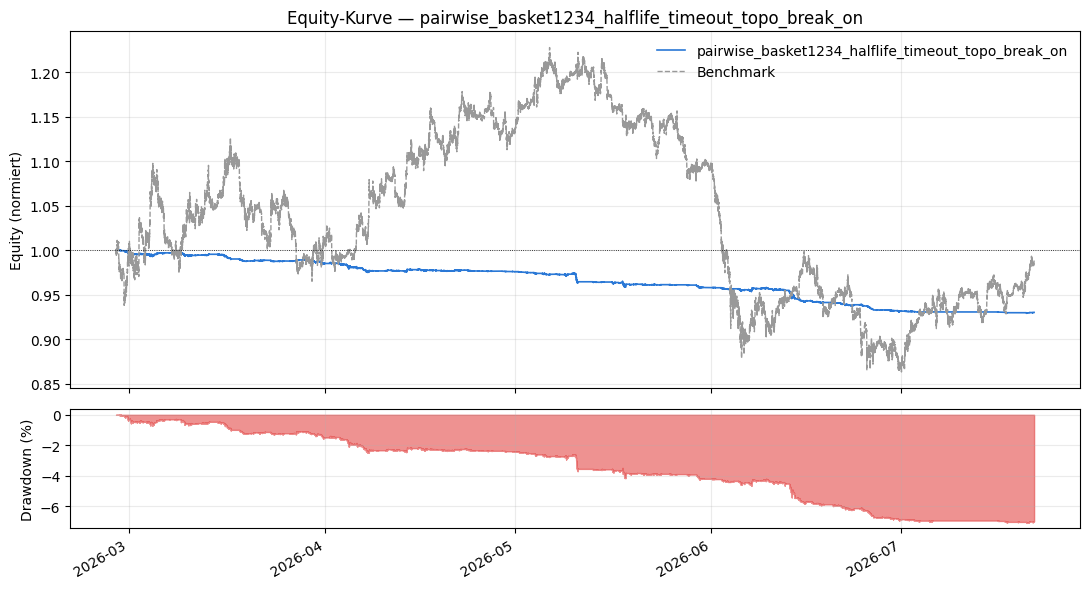

(<Figure size 1100x600 with 2 Axes>,
 (<Axes: title={'center': 'Equity-Kurve — pairwise_basket1234_halflife_timeout_topo_break_on'}, ylabel='Equity (normiert)'>,
  <Axes: ylabel='Drawdown (%)'>))

In [10]:
bt_plots.plot_equity_and_drawdown(result, benchmark_close=benchmark_close)

## 7. Trade-Analyse

`plot_exit_reason_breakdown` zeigt die Verteilung der **Breaks** (`target`/`stop`/`timeout`/`clique_break`/`data_gap`, siehe Strategie-Überblick oben) -- ein hoher `stop`- oder `timeout`-Anteil ist ein Warnsignal für falsch kalibrierte Bänder bzw. Half-Life-Filter. `plot_pnl_vs_diagnostic(..., "half_life_periods")` prüft direkt, ob Paare mit schnellerer Half-Life tatsächlich profitabler waren.

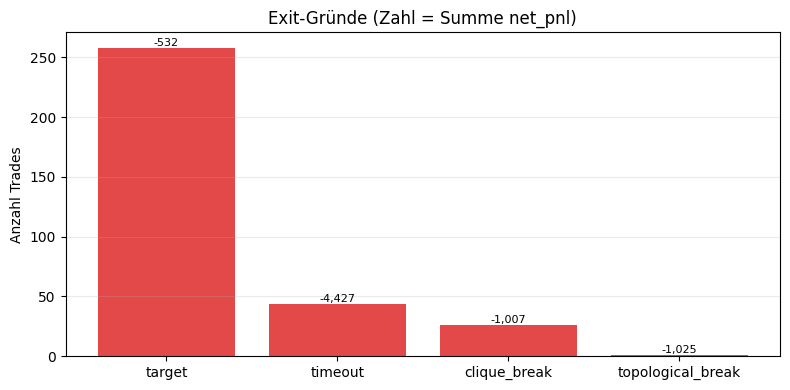

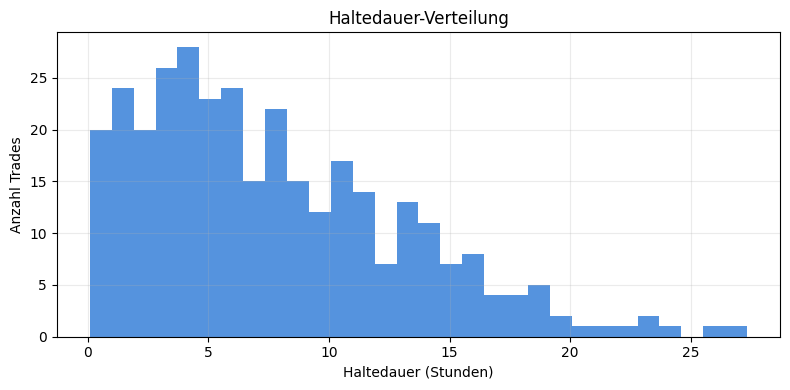

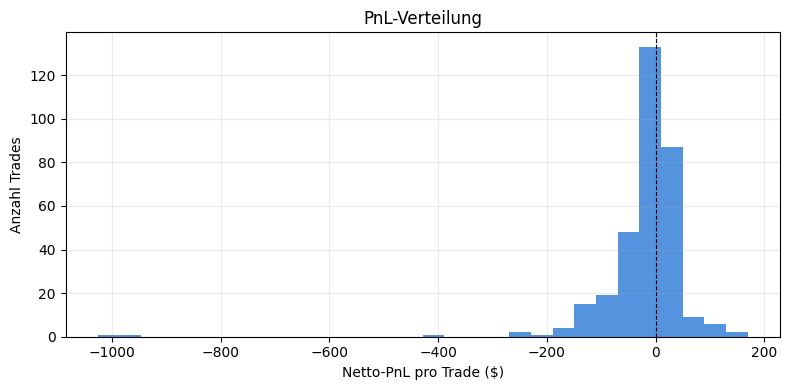

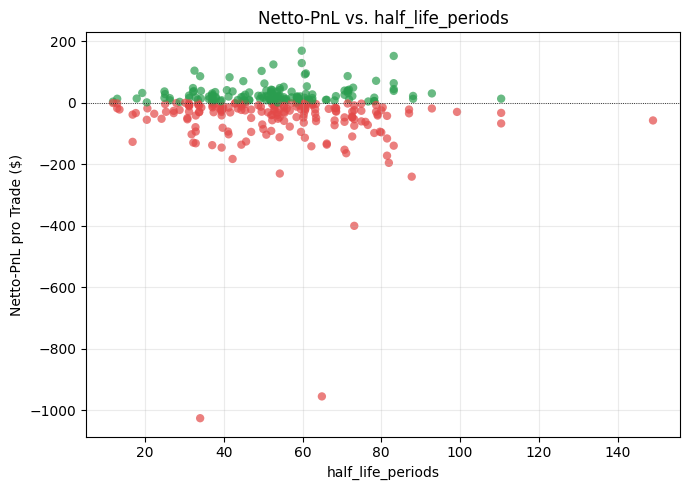

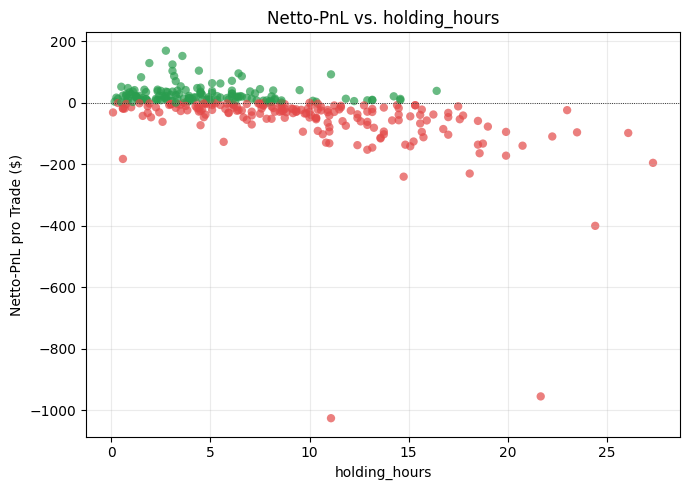

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'Netto-PnL vs. holding_hours'}, xlabel='holding_hours', ylabel='Netto-PnL pro Trade ($)'>)

In [11]:
bt_plots.plot_exit_reason_breakdown(result.trades)
bt_plots.plot_holding_period_histogram(result.trades)
bt_plots.plot_pnl_distribution(result.trades)
bt_plots.plot_pnl_vs_diagnostic(result.trades, "half_life_periods")
bt_plots.plot_pnl_vs_diagnostic(result.trades, "holding_hours")


### 7b. Beispiel-Trades mit Bollinger-Bändern

Rekonstruiert für einzelne Trades den Spread (log-Preis-Kombination der Beine, mit `weights` aus `SpreadDefinition`) über den Zeitraum um Entry/Exit und zeichnet die rollierenden Bollinger-Bänder (±`entry_z`/`exit_z`/`stop_z` * rollierende Std, `bollinger_window_candles` Fenster) darüber -- exakt dasselbe Band, das `SpreadDefinition.rolling_zscore` live für die Entscheidung ausgewertet hat. Auswahl gemischt über `exit_reason` (`_pick_sample_trades`), damit sowohl `target`- als auch `timeout`/`stop`/`clique_break`-Fälle zu sehen sind.

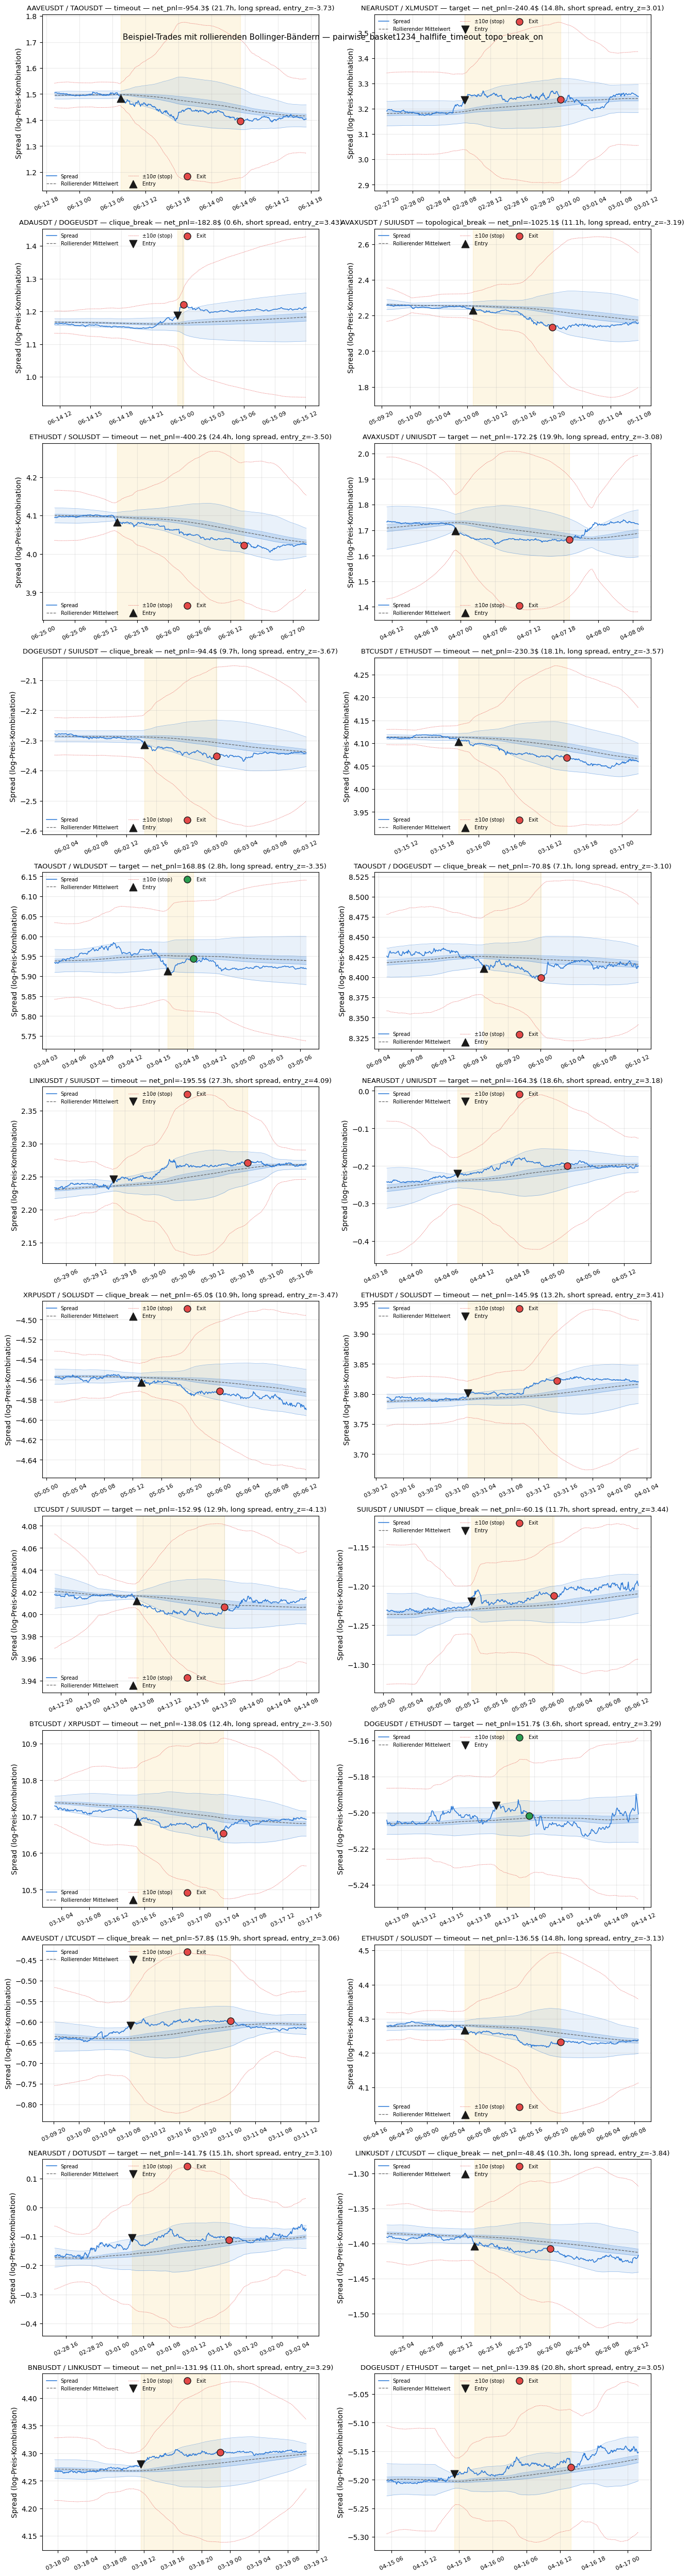

(<Figure size 1300x5040 with 24 Axes>,
 array([[<Axes: title={'center': 'AAVEUSDT / TAOUSDT — timeout — net_pnl=-954.3$ (21.7h, long spread, entry_z=-3.73)'}, ylabel='Spread (log-Preis-Kombination)'>,
         <Axes: title={'center': 'NEARUSDT / XLMUSDT — target — net_pnl=-240.4$ (14.8h, short spread, entry_z=3.01)'}, ylabel='Spread (log-Preis-Kombination)'>],
        [<Axes: title={'center': 'ADAUSDT / DOGEUSDT — clique_break — net_pnl=-182.8$ (0.6h, short spread, entry_z=3.43)'}, ylabel='Spread (log-Preis-Kombination)'>,
         <Axes: title={'center': 'AVAXUSDT / SUIUSDT — topological_break — net_pnl=-1025.1$ (11.1h, long spread, entry_z=-3.19)'}, ylabel='Spread (log-Preis-Kombination)'>],
        [<Axes: title={'center': 'ETHUSDT / SOLUSDT — timeout — net_pnl=-400.2$ (24.4h, long spread, entry_z=-3.50)'}, ylabel='Spread (log-Preis-Kombination)'>,
         <Axes: title={'center': 'AVAXUSDT / UNIUSDT — target — net_pnl=-172.2$ (19.9h, long spread, entry_z=-3.08)'}, ylabel='Spread (l

In [12]:
bt_plots.plot_sample_trades_bollinger(result, panel, n=24)

### Topologischer Struktur-Break: Zensiert-Diagnose

Nur relevant, wenn `TOPO_BREAK_ENABLED=True`. `epsilon_cap` (1.0 raw / 1.3 residual) ist bewusst nicht neu kalibriert -- laut `05_topological_break.ipynb` sind ca. 58.6% aller Cliquen "zensiert" (`death == epsilon_cap`, kein beobachteter Verschmelzungspunkt, siehe dortige Analyse). Zeigt, wie viele der `topological_break`-Exits hier eine zensierte `entry_death` hatten, statt das im Hintergrund zu verstecken.

In [13]:
if TOPO_BREAK_ENABLED:
    epsilon_cap_lookup = 1.0 if CLIQUE_VARIANT.startswith("raw") else 1.3
    topo_trades = result.trades.loc[result.trades["exit_reason"] == "topological_break"]
    n_topo = len(topo_trades)
    n_total = len(result.trades)
    print(f"topological_break: {n_topo} von {n_total} Trades ({100 * n_topo / n_total:.1f}%)" if n_total else "keine Trades")
    if n_topo:
        n_censored = int((topo_trades["entry_death"] >= epsilon_cap_lookup - 1e-9).sum())
        print(f"  davon mit zensiertem entry_death (== epsilon_cap={epsilon_cap_lookup}): {n_censored}/{n_topo} ({100 * n_censored / n_topo:.1f}%)")

    print("\nAufschluesselung nach Basket:")
    for b in BASKETS:
        b_total = int((result.trades["basket"] == b).sum())
        b_topo = int(((result.trades["basket"] == b) & (result.trades["exit_reason"] == "topological_break")).sum())
        print(f"  {b}: {b_topo} von {b_total} Trades ({100 * b_topo / b_total:.1f}%)" if b_total else f"  {b}: keine Trades")
else:
    print("TOPO_BREAK_ENABLED=False -- keine Diagnose (Regel war in diesem Run inaktiv).")


topological_break: 1 von 329 Trades (0.3%)
  davon mit zensiertem entry_death (== epsilon_cap=1.0): 0/1 (0.0%)

Aufschluesselung nach Basket:
  Basket 1: 0 von 127 Trades (0.0%)
  Basket 2: 1 von 161 Trades (0.6%)
  Basket 3: 0 von 29 Trades (0.0%)
  Basket 4: 0 von 12 Trades (0.0%)


## 8. Run speichern

In [14]:
run_dir = bt_runs.save_run(result)
print(f"Gespeichert: {result.run_id}")
print(run_dir)

Gespeichert: 20260813-124113_pairwise-basket1234-halflife-timeout-topo-break-on_7485d273
/Users/ryanmikus/Development/Python/00_Quant/26FS_BA/data/processed/backtests/20260813-124113_pairwise-basket1234-halflife-timeout-topo-break-on_7485d273


## 9. Vergleich mit früheren Runs

In [15]:
display(bt_runs.list_runs(refresh_index=True).tail(10))

,run_id,created_at,label,description,strategy_name,clique_variant,baskets,backtest_start,backtest_end,fingerprint,n_trades,sharpe_daily,cagr_daily,max_drawdown_pct,runtime_seconds
13,20260811-161145_pairwise-basket1234-topo-break...,2026-08-11T16:11:45.777566+00:00,pairwise_basket1234_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,"[Basket 1, Basket 2, Basket 3, Basket 4]",2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,7b320681,217,-7.241190,-0.171392,-0.073187,59.386479
14,20260811-160944_pairwise-basket1234-topo-break...,2026-08-11T16:09:44.099375+00:00,pairwise_basket1234_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,"[Basket 1, Basket 2, Basket 3, Basket 4]",2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,141682cf,212,-7.251162,-0.169602,-0.072392,34.072010
15,20260811-160539_pairwise-basket1-topo-break-on...,2026-08-11T16:05:39.281932+00:00,pairwise_basket1_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,8cf8b893,76,-4.297511,-0.066698,-0.030673,19.793534
16,20260811-160444_pairwise-basket1-topo-break-of...,2026-08-11T16:04:44.391237+00:00,pairwise_basket1_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3782a41a,76,-4.297511,-0.066698,-0.030673,9.136886
17,20260811-005244_pairwise-basket1-residual-24h_...,2026-08-11T00:52:44.080658+00:00,pairwise_basket1_residual_24h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5b80acd7,5,-1.321198,-0.003622,-0.003639,2.249917
18,20260811-005231_pairwise-basket1-residual-12h_...,2026-08-11T00:52:31.073432+00:00,pairwise_basket1_residual_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5eb79671,12,-2.705278,-0.015151,-0.007469,1.218577
19,20260811-005219_pairwise-basket1-residual-6h_3...,2026-08-11T00:52:19.094698+00:00,pairwise_basket1_residual_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3a38b525,6,-2.359453,-0.007265,-0.004354,2.005559
20,20260811-005206_pairwise-basket1-raw-12h_73ae444b,2026-08-11T00:52:06.223666+00:00,pairwise_basket1_raw_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,73ae444b,130,-4.562500,-0.075088,-0.036685,9.066313
21,20260811-005146_pairwise-basket1-raw-6h_6d7ff157,2026-08-11T00:51:46.243373+00:00,pairwise_basket1_raw_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,6d7ff157,115,-4.774419,-0.076830,-0.036143,9.118448
22,20260811-004926_pairwise-basket1-baseline_f58a...,2026-08-11T00:49:26.367598+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,f58a3bd8,76,-4.297511,-0.066698,-0.030673,10.668369


In [16]:
# Konkrete Runs zum Vergleich eintragen, z.B.:
# bt_runs.compare_runs([result.run_id, "<anderer-run-id>"])

## 10. Kosten-Sensitivität: existiert überhaupt ein Edge vor Kosten?

Der Baseline-Lauf oben (Abschnitt 4-9) zeigte `cost_pct_of_gross_profit ≈ 93.5%` -- Gebühren (`fee_bps=10`) und Slippage (`slippage_bps=2`) fressen fast den gesamten Bruttogewinn auf. Dieser Abschnitt trennt Signal- von Kosteneffekt: derselbe Backtest, dieselben Signale (`DEFAULT_PARAMS`, unverändert `entry_z=3.0`/`exit_z=0.5`), aber `fee_bps=0`/`slippage_bps=0` -- reiner Diagnose-Lauf, keine realistische Performance-Zahl. Zeigt er einen klaren Edge, ist das Problem "zu oft/zu teuer gehandelt" (lösbar über weniger Turnover, z.B. `ClusterSpreadStrategy`, oder günstigere Gebühren). Bleibt er auch ohne Kosten flach/negativ, liegt das Problem beim Signal selbst, nicht bei den Kosten.

In [17]:
from dataclasses import replace

ZERO_COST_PARAMS = replace(DEFAULT_PARAMS, fee_bps=0.0, slippage_bps=0.0)

config_zero_cost = BacktestConfig(
    label="pairwise_basket1234_halflife_timeout_topo_break_on_zero_cost",
    description=(
        "Diagnose-Lauf (KEINE realistische Performance-Zahl): identisch zu "
        f"{RUN_LABEL!r}, aber fee_bps=0/slippage_bps=0 -- zeigt, ob vor Kosten "
        "ueberhaupt ein Edge existiert (siehe Abschnitt 11)."
    ),
    calibration_range=CALIBRATION_RANGE, backtest_range=BACKTEST_RANGE,
    baskets=BASKETS, clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
    default_params=ZERO_COST_PARAMS, initial_capital=INITIAL_CAPITAL,
)

engine_zero_cost = BacktestEngine(config=config_zero_cost, panel=panel, timeline=timeline)
result_zero_cost = engine_zero_cost.run(progress=True)

result_zero_cost.metrics = bt_metrics.compute_all_metrics(
    equity_curve=result_zero_cost.equity_curve, trades=result_zero_cost.trades,
    benchmark_close=benchmark_close, config=config_zero_cost,
)
result_zero_cost.metrics_by_basket = bt_metrics.metrics_by_basket(result_zero_cost.trades, config_zero_cost)

run_dir_zero_cost = bt_runs.save_run(result_zero_cost)
print(f"Gespeichert: {result_zero_cost.run_id}")
display(result_zero_cost.summary())
display(result_zero_cost.metrics_by_basket)

100%|██████████| 41761/41761 [01:33<00:00, 444.73it/s] 


Gespeichert: 20260813-124247_pairwise-basket1234-halflife-timeout-topo-break-on-zero-cost_f056b93e


total_return                                                                  0.006505
cagr_bar                                                                      0.016455
ann_volatility_bar                                                            0.024836
sharpe_bar                                                                    0.669578
sortino_bar                                                                   0.942806
calmar_bar                                                                    0.902367
cagr_daily                                                                     0.01727
ann_volatility_daily                                                          0.025164
sharpe_daily                                                                  0.692963
sortino_daily                                                                 0.844203
calmar_daily                                                                  1.047717
max_drawdown_pct                           

,n_trades,n_winners,n_losers,win_rate,profit_factor,expectancy,avg_win,avg_loss,payoff_ratio,largest_win,largest_loss,avg_holding_candles,avg_holding_hours,median_holding_hours,max_holding_hours,avg_return_on_notional,exit_reason_counts,pct_forced_exits
basket,,,,,,,,,,,,,,,,,,
Basket 1,127,88,39,0.692913,1.587608,9.762755,38.067042,-54.103326,0.703599,181.283982,-405.535995,97.314961,8.109580,6.416667,26.083333,0.000971,"{""target"": 108, ""timeout"": 12, ""clique_break"": 7}",0.0
Basket 2,161,107,54,0.664596,1.154232,3.185597,35.871656,-61.581225,0.582510,122.348609,-1048.443499,85.925466,7.160455,6.333333,27.333333,0.000320,"{""target"": 121, ""timeout"": 27, ""clique_break"":...",0.0
Basket 3,29,13,16,0.448276,0.227279,-58.019055,38.068192,-136.089944,0.279728,77.067063,-992.022714,110.827586,9.235632,8.083333,21.666667,-0.005727,"{""target"": 21, ""clique_break"": 6, ""timeout"": 2}",0.0
Basket 4,12,8,4,0.666667,4.222628,48.357988,95.045623,-45.017282,2.111314,193.227308,-106.022205,77.416667,6.451389,6.291667,11.000000,0.004813,"{""target"": 8, ""timeout"": 3, ""clique_break"": 1}",0.0


In [18]:
print("Baseline (echte Kosten) vs. Diagnose OHNE Kosten:")
display(bt_runs.compare_runs([result.run_id, result_zero_cost.run_id]))

print("\nnach Basket:")
display(bt_runs.compare_runs([result.run_id, result_zero_cost.run_id], by_basket=True))

Baseline (echte Kosten) vs. Diagnose OHNE Kosten:


,20260813-124113_pairwise-basket1234-halflife-timeout-topo-break-on_7485d273,20260813-124247_pairwise-basket1234-halflife-timeout-topo-break-on-zero-cost_f056b93e
cagr_daily,-0.165614,0.017270
ann_volatility_daily,0.024581,0.025164
sharpe_daily,-7.351811,0.692963
sortino_daily,-7.128721,0.844203
calmar_daily,-2.366162,1.047717
max_drawdown_pct,-0.070981,-0.018236
max_drawdown_dollar,-7098.341595,-1862.832827
beta_vs_benchmark,0.000865,0.000999
alpha_annualized_vs_benchmark,-0.165395,0.017544
n_trades,329.000000,329.000000



nach Basket:


20260813-124113_pairwise-basket1234-halflife-timeout-topo-break-on_7485d273  \
basket   metric                                                                                               
Basket 1 n_trades                                                              127                            
         n_winners                                                              60                            
         n_losers                                                               67                            
         win_rate                                                         0.472441                            
         profit_factor                                                    0.461361                            
...                                                                            ...                            
Basket 4 median_holding_hours                                             6.291667                            
         max_holding_hours                                                    11.0                            
         avg_return_on_notional                                           0.002421                            
         exit_reason_counts         {"target": 8, "timeout": 3, "clique_break": 1}                            
         pct_forced_exits                                                      0.0                            

                                20260813-124247_pairwise-basket1234-halflife-timeout-topo-break-on-zero-cost_f056b93e  
basket   metric                                                                                                        
Basket 1 n_trades                                                              127                                     
         n_winners                                                              88                                     
         n_losers                                                               39                                     
         win_rate                                                         0.692913                                     
         profit_factor                                                    1.587608                                     
...                                                                            ...                                     
Basket 4 median_holding_hours                                             6.291667                                     
         max_holding_hours                                                    11.0                                     
         avg_return_on_notional                                           0.004813                                     
         exit_reason_counts         {"target": 8, "timeout": 3, "clique_break": 1}                                     
         pct_forced_exits                                                      0.0                                     

[72 rows x 2 columns]